# Compte Rendu du TP 1 : Apprentissage supervisé avec Scikitlearn
Réalisé par : Majdi Jalal (N°28)

## Pour télécharger les datasets utilisés dans le TP
- Uber : [Lien Kaggle](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset)
- Titanic : [Lien Kaggle](https://www.kaggle.com/c/titanic/data)
- Diabetes : [Lien Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

<p style="color:blue; font-weight:bold;">Objectifs</p>

- Comprendre et appliquer les étapes d’un apprentissage supervisé.
- Manipuler des modèles de régression et de classification avec Scikit-learn.
- Savoir préparer, entraîner, évaluer et interpréter un modèle.

<h2 style="color: #c0392b;">Exercice 1 — Régression : Prédiction du tarif d’un trajet Uber</h2>

**Régression** est une technique qui consiste à prédire une valeur numérique continue à partir de variables d'entrée.

Dans cet exercice on applique la régression sur la prédiction du tarif d'un trajet Uber , voici quelque informations sur les colonnes de cet dataset : 
- **key** : un identifiant unique pour chaque trajet
- **fare_amount** : le coût de chaque trajet en $
- **pickup_datetime** : date et heure auxquelles le compteur a été enclenché (début de la course)
- **passenger_count** : le nombre de passagers dans le véhicule (valeur saisie par le conducteur)
- **pickup_longitude** : la longitude du lieu de prise en charge (où le compteur a été enclenché)
- **pickup_latitude** : la latitude du lieu de prise en charge (où le compteur a été enclenché)
- **dropoff_longitude** : la longitude du lieu de dépose (où le compteur a été arrêté)
- **dropoff_latitude** : la latitude du lieu de dépose (où le compteur a été arrêté)


<p style="color:blue; font-weight:bold;">Étape 1 : Chargement et exploration du jeu de données</p>

In [1]:
import pandas as pd
data = pd.read_csv('uber.csv')
#Afficher les 5 premiers lignes
print(data.head())
#Afficher les informations sur les colonnes
print(data.info())
#Afficher le nombre des valeurs nulles par colonne
print(data.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

<p style="color:blue; font-weight:bold;">Étape 2 : Nettoyage et préparation</p>

Pour avoir des bonnes prédictions , on doit assurer que la dataset est nettoyé , pour cela on doit : 
  - Assurer que les colonnes ont le bon type.
  - Supprimer les valeurs manquantes.
  - Retirer les valeurs aberrantes.
  - Créer des variables dérivées.

In [2]:
#Affichage des lignes avec des valeurs NA
data[data.isnull().any(axis=1)]


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
87946,32736015,2013-07-02 03:51:57.0000001,24.1,2013-07-02 03:51:57 UTC,-73.950581,40.779692,NaN,NaN,0


In [3]:
#Affichage des lignes ou le prix est négative
data[data['fare_amount']<0]

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
63395,30260042,2015-03-03 23:07:41.0000008,-5.00,2015-03-03 23:07:41 UTC,-73.992249,40.748936,-73.988518,40.748180,1
71246,51325304,2010-02-11 21:47:10.0000001,-3.30,2010-02-11 21:47:10 UTC,-73.952725,40.768235,-73.949928,40.772208,2
79903,50284253,2015-05-01 14:43:02.0000004,-3.50,2015-05-01 14:43:02 UTC,-73.982430,40.775024,-73.981750,40.778439,1
89322,26673143,2010-03-09 08:26:10.0000006,-49.57,2010-03-09 08:26:10 UTC,-73.972772,40.785657,-73.972867,40.785500,5
92063,10267585,2010-03-12 08:49:10.0000002,-23.70,2010-03-12 08:49:10 UTC,-73.952740,40.768233,-74.007028,40.707338,3
98875,51135168,2015-03-20 21:31:14.0000007,-52.00,2015-03-20 21:31:14 UTC,-74.000359,40.728729,-74.005699,40.728680,5
104080,21688700,2010-03-09 20:25:10.0000002,-7.30,2010-03-09 20:25:10 UTC,-73.952623,40.766942,-73.953787,40.784882,1
111589,13971251,2015-02-23 19:26:44.0000004,-52.00,2015-02-23 19:26:44 UTC,-73.984665,40.759026,0.000000,0.000000,5
139272,40714150,2010-02-23 18:52:10.0000003,-6.90,2010-02-23 18:52:10 UTC,-73.988727,40.736445,-73.977622,40.750487,1
148803,34933571,2010-02-12 10:50:10.0000005,-5.70,2010-02-12 10:50:10 UTC,-73.977300,40.742783,-73.988837,40.747465,3


In [4]:
#Eliminer les lignes qui ont des valeurs manquantes.
data = data.dropna()
#Le prix ne peut pas être négative
data = data[data['fare_amount'] > 0]
#Les dates doivent être casté de string --> datetime
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
#On extract l'heure et le nombre du jour (0:Lundi ---- 6:Samedi)
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek



Notre dataset contient la latitude et la longitude du lieu de départ (pickup) et d'arrivée. On doit utiliser ces informations pour calculer la distance du trajet. Pour faire cela, on utilise la relation de Haversine suivante :

$$
a = \sin^2\left(\frac{\Delta\phi}{2}\right) + \cos(\phi_1) \cdot \cos(\phi_2) \cdot \sin^2\left(\frac{\Delta\lambda}{2}\right)
$$

$$
c = 2 \cdot \text{atan2}\left(\sqrt{a}, \sqrt{1-a}\right)
$$

$$
d = R \cdot c
$$

Où $\phi$ est la latitude, $\lambda$ est la longitude, et $R$ est le rayon de la Terre (environ 6371 km).

In [5]:
import numpy as np

def haversine_distance(lat1, lon1, lat2, lon2):
    # Conversion vers radian
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    # Application de la forumle
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    # Multiplication par le rayon de la terre pour avoir la distance en km
    r = 6371
    return c * r

# Appel de la fonction
data['distance_km'] = haversine_distance(
    data['pickup_latitude'].values, 
    data['pickup_longitude'].values,
    data['dropoff_latitude'].values, 
    data['dropoff_longitude'].values
)

In [6]:
#Vérification des changements :
data.info()
data.head()

<class 'pandas.DataFrame'>
Index: 199977 entries, 0 to 199999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   Unnamed: 0         199977 non-null  int64              
 1   key                199977 non-null  str                
 2   fare_amount        199977 non-null  float64            
 3   pickup_datetime    199977 non-null  datetime64[us, UTC]
 4   pickup_longitude   199977 non-null  float64            
 5   pickup_latitude    199977 non-null  float64            
 6   dropoff_longitude  199977 non-null  float64            
 7   dropoff_latitude   199977 non-null  float64            
 8   passenger_count    199977 non-null  int64              
 9   hour               199977 non-null  int32              
 10  day_of_week        199977 non-null  int32              
 11  distance_km        199977 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(6), int32(2

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,distance_km
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,3,1.683323
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,4,2.457590
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,0,5.036377
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,4,1.661683
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,3,4.475450


<p style="color:blue; font-weight:bold;">Étape 3 : Séparation des données</p>

Pour pouvoir juger la précision de nos prédicitions , il est important de séparer la dataset en deux parties : partie de training et partie de test.
Pour faire cela on utilise la fonction *train_test_split* de **sickit-learn**.

In [7]:
from sklearn.model_selection import train_test_split
#Selection des features
X = data[['distance_km', 'hour', 'day_of_week']]
#Selection du target
y = data['fare_amount']

#80% pour le training , 20% pour le test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



<p style="color:blue; font-weight:bold;">Étape 4 : Entraînement du modèle</p>

On choisit le modèle de regression linèaire, on entraine le modèle en utilisant *.fit*


In [8]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

**Comparaison de quelques valeurs**

In [9]:
comparison = pd.DataFrame({
    'Valeur Réelle': y_test.values,
    'Prédiction': y_pred
})

comparison['Erreur Absolue'] = (comparison['Valeur Réelle'] - comparison['Prédiction']).abs()

comparison.head(20)

,Valeur Réelle,Prédiction,Erreur Absolue
0,5.7,11.792285,6.092285
1,8.1,11.216311,3.116311
2,8.5,10.979748,2.479748
3,8.1,11.357942,3.257942
4,7.7,11.299514,3.599514
5,11.0,10.982265,0.017735
6,23.5,11.154495,12.345505
7,12.5,11.704247,0.795753
8,10.5,11.558695,1.058695
9,6.5,11.324694,4.824694


<p style="color:blue; font-weight:bold;">Étape 5 : Évaluation du modèle</p>

On utilise trois métriques pour évaluer le model :
 - **MSE** : mean squared error. $ \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $
 - **RMSE** : root mean squared error. $ \text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2} $
 - **R2 score** : Coefficient de détermination. $ R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} $


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print('MAE =', mae)
print('RMSE =', rmse)
print('R² =', r2)

MAE = 6.024606980536918
RMSE = 9.635978518193681
R² = 0.0014590917488974675


On remarque que les prédictions sont en général loin des valeurs réels.
Les résultats montrent que le modèle a un R² très faible (0.0015), ce qui signifie qu'il n'arrive pas à expliquer la variance des tarifs. L'erreur moyenne (MAE) est d'environ 6 indiquant la présence d'erreurs importantes sur certains trajets.

Cela s'explique par le fait que la distance et les coordonnées géographiques ne suffisent pas à prédire le prix d'une course. Le tarif dépend de facteurs non présents dans le dataset, comme le trafic, les péages,etc... . De plus, une régression linéaire simple est probablement trop basique pour capturer la complexité de ces données.

<p style="color:blue; font-weight:bold;">Étape 6 : Amélioration avec Random Forest</p>

Dans le but d'améliorer les résultats, on va utiliser ***Random Forest*** : un modèle d'ensemble qui construit une multitude d'arbres de décision indépendants et moyenne leurs prédictions. Cette approche permet de réduire le sur-apprentissage (overfitting) et de mieux capturer les relations non-linéaires qu'une simple régression.


In [11]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)


**Comparaison de quelques valeurs**

In [12]:
comparison = pd.DataFrame({
    'Valeur Réelle': y_test.values,
    'Prédiction': y_pred_rf
})

comparison['Erreur Absolue'] = (comparison['Valeur Réelle'] - comparison['Prédiction']).abs()

comparison.head(20)

,Valeur Réelle,Prédiction,Erreur Absolue
0,5.7,6.4430,0.7430
1,8.1,9.7430,1.6430
2,8.5,6.3470,2.1530
3,8.1,7.7620,0.3380
4,7.7,9.3630,1.6630
5,11.0,14.3580,3.3580
6,23.5,13.5530,9.9470
7,12.5,14.9860,2.4860
8,10.5,8.7030,1.7970
9,6.5,5.5390,0.9610


In [13]:
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)
print('MAE =', mae)
print('RMSE =', rmse)
print('R² =', r2)

MAE = 2.677294876669236
RMSE = 5.246006625735057
R² = 0.7040407725365974


<p style="font-size:19px;font-weight:bold;">Interpretation des résultats</p>
Le passage de la régression linéaire à un modèle d'ensemble (Random Forest) a permis une amélioration spectaculaire des performances. Le R² passe de 0.0014 à 0.704, ce qui signifie que le modèle explique désormais 70% de la variance des tarifs. L'erreur moyenne absolue (MAE) a chuté à 2.68. 
Le Random Forest a donc permis de capturer les relations non-linéaires entre la distance, les variables temporelles et le prix.

<p style="color:blue; font-weight:bold;">Étape 6 : Amélioration avec Random Forest</p>
on utilise matplotlib pour visualiser

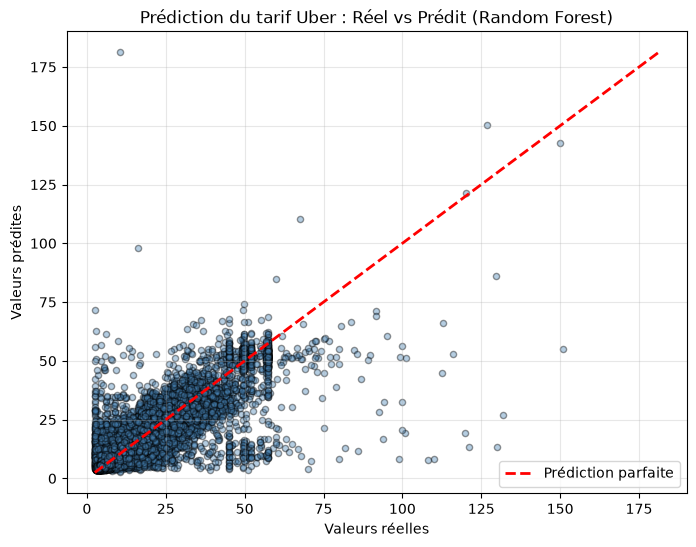

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.4, color='steelblue', edgecolor='k', s=20)


min_val = min(y_test.min(), y_pred_rf.min())
max_val = max(y_test.max(), y_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Prédiction parfaite')

plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber : Réel vs Prédit (Random Forest)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Analyse graphique des prédictions :**

Le graphique de dispersion des valeurs réelles en fonction des valeurs prédites montre une bonne corrélation linéaire. Les points se concentrent majoritairement autour de la diagonale rouge (y=x), ce qui confirme visuellement le R² de 0.70 obtenu. Cependant, on observe une dispersion plus importante pour les tarifs élevés (supérieurs à 40$), indiquant que le modèle est moins précis sur les courses onéreuses. Cela suggère que d'autres variables manquent dans notre dataset pour mieux expliquer ces tarifs.

<h2 style="color: #c0392b;">Exercice 2 — Classification : Prédire la survie sur le Titanic</h2>


**Classification** : est une technique qui consiste à prédire une catégorie ou une classe discrète (par exemple : spam ou non-spam) à partir de variables d'entrée.
Dans cet exrcice on applique la ***classification binaire*** , le but est de prédire si un passager a survécu (1) ou non (0) non au naufrage.

**Dictionnaire des données**:
| Variable | Définition | Signification |
| :--- | :--- | :--- |
| `survival` | Survie | 0 = Non, 1 = Oui |
| `pclass` | Classe du billet | 1 = 1ère, 2 = 2ème, 3 = 3ème |
| `sex` | Sexe | |
| `Age` | Âge en années | |
| `sibsp` | Nombre de frères/sœurs ou conjoints à bord | |
| `parch` | Nombre de parents ou enfants à bord | |
| `ticket` | Numéro du billet | |
| `fare` | Tarif du passager | |
| `cabin` | Numéro de cabine | |
| `embarked` | Port d'embarquement | C = Cherbourg, Q = Queenstown, S = Southampton |

<p style="color:blue; font-weight:bold;">Étape 1 : Chargement et exploration</p>

In [15]:
data = pd.read_csv('titanic.csv')
print(data.head())
print(data.info())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

<p style="color:blue; font-weight:bold;">Étape 2 : Nettoyage et traitement</p>

Les traitements réalisés : 

  -Choix des colonnes.
  
  -Traitement des valeurs aberrantes (remplacement par médian ou par mode).

  -Créer une nouvelle feature 'FamilySize' qui regroupe les deux colonnes 'SibSp' et 'Parch'.

In [16]:
data = data[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])


data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data = data.drop(['SibSp', 'Parch'], axis=1)


<p style="color:blue; font-weight:bold;">Étape 3 : Encodage des variables catégorielles</p>

  -Transformer les colonnes 'Sex' et 'Embarked' en indice :
   
    + 0:female , 1:male.
    + 0:Cherbourg , 1:Queenstown , Southampton:2.



In [17]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

print(data.head())
data.info()

   Survived  Pclass  Sex   Age     Fare  Embarked  FamilySize
0         0       3    1  22.0   7.2500         2           2
1         1       1    0  38.0  71.2833         0           2
2         1       3    0  26.0   7.9250         2           1
3         1       1    0  35.0  53.1000         2           2
4         0       3    1  35.0   8.0500         2           1
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   Fare        891 non-null    float64
 5   Embarked    891 non-null    int64  
 6   FamilySize  891 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 48.9 KB


<p style="color:blue; font-weight:bold;">Étape 4 : Séparation des données</p>


In [18]:
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train :", X_train.shape)
print(f"X_test :", X_test.shape)
print(f"y_train :", y_train.shape)
print(f"y_test :",y_test.shape)

X_train : (712, 6)
X_test : (179, 6)
y_train : (712,)
y_test : (179,)


<p style="color:blue; font-weight:bold;">Étape 5 : Entraînement des modèles</p>

On utilise deux méthodes différentes de classification :

 -**Logisitic Regression** : un algorithme d'apprentissage supervisé utilisé pour la classification. Elle modélise la probabilité qu'une observation appartienne à une classe donnée (généralement binaire) en appliquant une fonction sigmoïde à une combinaison linéaire des variables d'entrée.
 
 -**Random forest classifier**: un algorithme d'ensemble qui combine les prédictions de multiples arbres de décision entraînés sur des sous-échantillons aléatoires des données. Pour la classification, il agrège les résultats par vote majoritaire afin d'attribuer la classe finale, ce qui réduit le sur-apprentissage et améliore la robustesse.


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

<p style="color:blue; font-weight:bold;">Étape 6 : Évaluation des modèles</p>

On compare la précision des prédicitions entre les deux modèles utilisés, pour cela on utilise deux métriques :
  - **accuracy_score** : le pourcentage de prédictions correctes sur l'ensemble des prédictions.
  - **classification_report** : donne trois indicateurs importants (***Precision***,***Recall***,***F1-score***)


In [20]:
from sklearn.metrics import accuracy_score, classification_report
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
print('Accuracy (Logistic):', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest):', accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic): 0.8044692737430168
Accuracy (Random Forest): 0.8268156424581006
              precision    recall  f1-score   support

           0       0.85      0.86      0.85       105
           1       0.79      0.78      0.79        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



<p style="font-size:19px;font-weight:bold;">Interpretation des résultats</p>


Les deux modèles obtiennent des performances satisfaisantes avec une accuracy de 80.4% pour la Régression Logistique et 82.6% pour le Random Forest. Le Random Forest est légèrement supérieur, confirmant sa capacité à capturer des relations non-linéaires entre les variables.

Le rapport de classification du Random Forest montre une différence de performance entre les deux classes : le F1-score est de 0.85 pour la classe "Non Survécu" contre 0.79 pour la classe "Survécu". Cette disparité s'explique par le déséquilibre des classes dans le dataset (plus de passagers décédés que de survivants). Le modèle est donc plus fiable pour prédire les décès que les survies, ce qui est une limite commune à ce type de problème.

<p style="color:blue; font-weight:bold;">Étape 7 : Matrice de confusion</p>

La **matrice de confusion** est un outil d'évaluation qui compare les étiquettes réelles aux étiquettes prédites par le modèle. Pour un problème binaire, elle se présente sous la forme d'une matrice 2x2 contenant quatre valeurs : les vrais positifs (VP), les vrais négatifs (VN), les faux positifs (FP) et les faux négatifs (FN). Elle permet d'identifier précisément le type d'erreurs commises par le modèle et de calculer des métriques dérivées comme la précision et le rappel.

| | Prédit : Non (0) | Prédit : Oui (1) |
| :--- | :---: | :---: |
| **Réel : Non (0)** | Vrais Négatifs (VN) | Faux Positifs (FP) |
| **Réel : Oui (1)** | Faux Négatifs (FN) | Vrais Positifs (VP) |


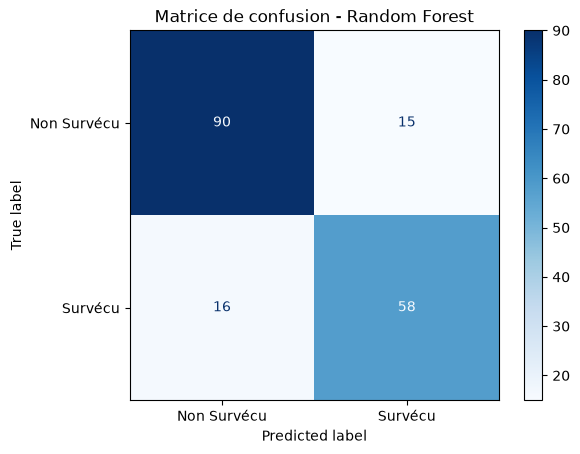

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non Survécu', 'Survécu'])
disp.plot(cmap='Blues')
plt.title('Matrice de confusion - Random Forest')
plt.show()



<p style="font-size:19px;font-weight:bold;">Interpretation des résultats</p>
La matrice de confusion confirme ce qu'on a déjà remarqué : 

  - Le modèle est très bon pour identifier les décès (90 bons résultats sur 105 réels, soit 86% de rappel).
  - Il est un peu moins performant pour identifier les survivants (58 bons résultats sur 74 réels, soit 78% de rappel)

<h2 style="color: #c0392b;">Partie 2 : Mini-projet et compte rendu</h2>

Presentation du Dataset: 

Dans cet partie je vais utilisé une dataset appelé ***diabetes_prediction_dataset*** téléchargé depuis Kaggle.

L'objectif est de classifier si le patient est diabete ou non en se basant sur plusieurs caractéristiques.

La dataset contient 8 features : genre,age,hypertension,heart_disease,smoking_history,bmi,Hb1ac_level,blood_glucose_level.


In [22]:
import pandas as pd

df = pd.read_csv("diabetes_prediction_dataset.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.describe())


(100000, 9)
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age              

In [23]:
df = df[df['gender'].isin(['Female', 'Male'])]
df = df.reset_index(drop=True)
#Voir le nombre des valeurs nulles
print(df.isnull().sum())
#Voir les differents valeurs de chaque colonne
print(df.apply(lambda col: col.unique()))


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
gender                                                    [Female, Male]
age                    [80.0, 54.0, 28.0, 36.0, 76.0, 20.0, 44.0, 79....
hypertension                                                      [0, 1]
heart_disease                                                     [1, 0]
smoking_history        [never, No Info, current, former, ever, not cu...
bmi                    [25.19, 27.32, 23.45, 20.14, 19.31, 23.86, 33....
HbA1c_level            [6.6, 5.7, 5.0, 4.8, 6.5, 6.1, 6.0, 5.8, 3.5, ...
blood_glucose_level    [140, 80, 158, 155, 85, 200, 145, 100, 130, 16...
diabetes                                                          [0, 1]
dtype: object


D'après les informations qu'on a eu du df.describe() , on peut regler les valeurs aberrantes.
 - Age doit être au moins un an (le min actuel est 0.08)
 - On le bmi est en general entre 10 et 60 , au dela de cette zone , cela peut affecter nos résultats.

In [24]:
df = df[df['age'] >= 1]
df['bmi'] = df['bmi'].clip(upper=60)



On applique One hot encoding sur les colonnes 'gender' et 'smoking_history'

In [25]:
df = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True)

# Vérifier le résultat
print(df.head())
print(df.columns.tolist())

    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   diabetes  gender_Male  smoking_history_current  smoking_history_ever  \
0         0        False                    False                 False   
1         0        False                    False                 False   
2         0         True                    False                 False   
3         0        False                     True                 False   
4         0         True                     True                 False   

   smoking_history_former  smoking_history_never  smoking_hist

La base de données est generalement nettoyé, donc on passe aux étapes suivantes:

 -On sépare la dataset en partie training et partie test

In [26]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print(f"X_train :", X_train.shape)
print(f"X_test :", X_test.shape)
print(f"y_train :", y_train.shape)
print(f"y_test :",y_test.shape)

X_train : (79256, 12)
X_test : (19815, 12)
y_train : (79256,)
y_test : (19815,)


On effectue le training en utilisant ***Logisitic Regression***.

In [27]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)

acc_log = accuracy_score(y_test, y_pred_log)


On effectue le training en utilisant ***Random Forest Classifier***.

In [28]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

Comparaison des résultats:

In [29]:
print(f"Accuracy (Régression Logistique) : {acc_log:.4f}")
print(f"Accuracy (Random Forest)         : {acc_rf:.4f}")

comparison = pd.DataFrame({
    'Valeur Réelle': y_test,
    'Prédiction Logistic': y_pred_log,
    'Prédiction Forest' : y_pred_rf
})


comparison.head(20)

Accuracy (Régression Logistique) : 0.9591
Accuracy (Random Forest)         : 0.9682


,Valeur Réelle,Prédiction Logistic,Prédiction Forest
41355,0,0,0
99379,0,0,0
26930,0,0,0
10619,0,0,0
6729,0,0,0
65209,0,0,0
7484,0,0,0
1896,0,0,0
93055,0,0,0
61803,0,0,0


In [30]:
print("\n--- Rapport de classification : Random Forest ---")
print(classification_report(y_test, y_pred_rf))


--- Rapport de classification : Random Forest ---
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     18100
           1       0.95      0.67      0.78      1715

    accuracy                           0.97     19815
   macro avg       0.96      0.83      0.88     19815
weighted avg       0.97      0.97      0.97     19815



Les deux modèles obtiennent des performances globales élevées (95.91% pour la Régression Logistique, 96.82% pour le Random Forest). Cependant, le dataset présente un fort déséquilibre des classes : 18100 patients non-diabétiques contre seulement 1715 diabétiques.

Cette asymétrie se reflète dans le rapport de classification : le modèle identifie parfaitement les patients sains (Recall = 1.00), mais ne détecte que 67% des patients diabétiques (Recall = 0.67). Autrement dit, 33% des diabétiques ne sont pas identifiés par le modèle, ce qui représente un enjeu clinique majeur. La précision élevée (0.95) indique que lorsque le modèle prédit un diabète, il a raison dans 95% des cas.

<p style="font-size:20px;font_weight:bold">Matrice de confusion</p>

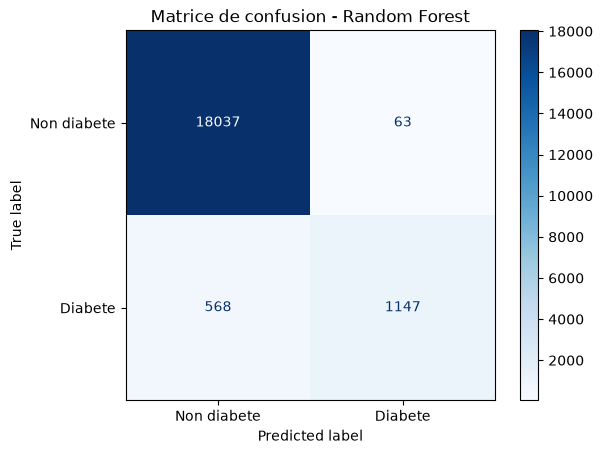

In [31]:

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non diabete', 'Diabete'])
disp.plot(cmap='Blues')
plt.title('Matrice de confusion - Random Forest')
plt.show()

***Analyse de la matrice de confusion :***

La matrice de confusion du Random Forest confirme le déséquilibre des classes observé. Sur 19 997 patients, le modèle identifie correctement 18037 non diabétiques (VN) et 1147 diabétiques (VP). Les erreurs sont très asymétriques : seulement 63 faux positifs (patients sains prédits diabétiques) contre 568 faux négatifs (patients diabétiques prédits sains).

Cela se traduit par un recall de seulement 0.67 pour la classe "Diabète" : le modèle manque 33% des cas réels. Ce comportement est dû au fort déséquilibre du dataset , qui pousse le modèle à privilégier la classe majoritaire. Pour un usage clinique, ce modèle n'est pas satisfaisant car il laisse trop de patients diabétiques sans diagnostic.

Afin de résoudre cela on ajoute ce paramètre class_weight='balanced' à notre model et on ressaie

In [32]:
rf_model_balanced = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced')
rf_model_balanced.fit(X_train, y_train)
y_pred_rf = rf_model_balanced.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)


In [33]:

print(acc_rf)
print("\n--- Rapport de classification : Random Forest Balanced ---")
print(classification_report(y_test, y_pred_rf))

0.9583648750946253

--- Rapport de classification : Random Forest Balanced ---
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     18100
           1       0.77      0.73      0.75      1715

    accuracy                           0.96     19815
   macro avg       0.87      0.86      0.87     19815
weighted avg       0.96      0.96      0.96     19815



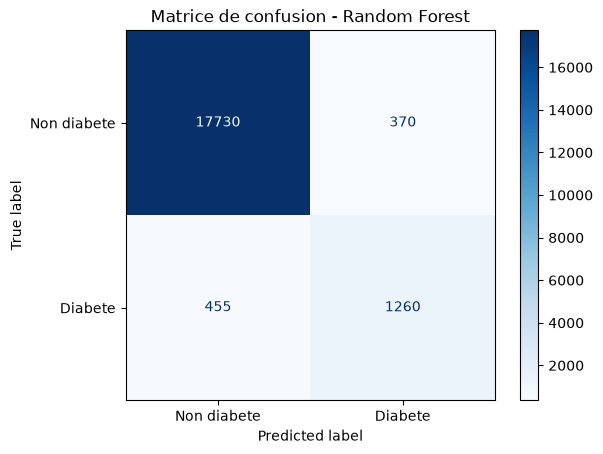

In [34]:

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non diabete', 'Diabete'])
disp.plot(cmap='Blues')
plt.title('Matrice de confusion - Random Forest')
plt.show()

**Interpretation**:

Pour corriger le biais du modèle en faveur de la classe majoritaire, nous avons entraîné un Random Forest avec le paramètre class_weight='balanced'. Les résultats montrent un compromis classique : l'accuracy globale baisse légèrement (de 96.82% à 95.8%), mais le rappel de la classe "Diabète" s'améliore significativement, passant de 0.67 à 0.73. Le modèle détecte donc davantage de patients diabétiques, au prix d'une précision plus faible (0.77 contre 0.95), c'est-à-dire plus de fausses alertes.

Ce compromis est particulièrement pertinent dans un contexte médical : il vaut mieux orienter quelques patients sains vers des tests supplémentaires que de laisser un patient diabétique sans diagnostic.

<h2 style="color: #c0392b;">Conclusion Générale</h2>

Ce TP nous a permis d'appliquer des techniques de régression et de classification sur plusieurs datasets aux caractéristiques variées (Uber, Titanic, Diabète). L'objectif était double : maîtriser le nettoyage des données et comparer différents modèles d'apprentissage supervisé pour en améliorer les performances.

Nous avons pu découvrir les différentes métriques à utiliser selon le contexte (régression ou classification) pour évaluer la précision des prédictions, ainsi que la matrice de confusion pour interpréter finement les résultats obtenus. 

Grâce à cette étude comparative et à l'interprétation des résultats, nous avons pu améliorer les prédictions et optimiser les performances de nos modèles.